# Install Requirements

In [89]:
!pip install numpy pandas scikit-learn torch

In [90]:
!pip install torch-geometric

# Start Coding for CMaps dataset

In [91]:
# =======================
# 0) Imports & Repro
# =======================
import os, math, random, numpy as np, pandas as pd
import torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


## Connect to Drive

In [92]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [93]:
# =======================
# 1) Load exactly as requested
# =======================
index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['sensor_{}'.format(i+1) for i in range(0,21)]
col_names = index_names + setting_names + sensor_names

base_path = '/content/drive/MyDrive/Colab Notebooks/Master/CMAPS/CMaps/'

dftrain = pd.read_csv(base_path + 'train_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
dfvalid = pd.read_csv(base_path + 'test_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
y_valid = pd.read_csv(base_path + 'RUL_FD001.txt',sep='\s+',header=None,index_col=False,names=['RUL'])

print("Train shape:", dftrain.shape, "Test shape:", dfvalid.shape, "y_valid shape:", y_valid.shape)



Train shape: (20631, 26) Test shape: (13096, 26) y_valid shape: (100, 1)


<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-1513358968.py:11: SyntaxWarning: invalid escape sequence '\s'
  dftrain = pd.read_csv(base_path + 'train_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
/tmp/ipython-input-1513358968.py:12: SyntaxWarning: invalid escape sequence '\s'
  dfvalid = pd.read_csv(base_path + 'test_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
/tmp/ipython-input-1513358968.py:13: SyntaxWarning: invalid escape sequence '\s'
  y_valid = pd.read_csv(base_path + 'RUL_FD001.txt',sep='\s+',header=None,index_col=False,names=['RUL'])


In [94]:
# =======================
# 2) Preprocess
#    - drop known-constant sensors
#    - z-score normalization (fit on train, apply to both)
#    - build sliding windows
# =======================
# Sensors known to be constant in C-MAPSS
CONST_SENS = ['sensor_1','sensor_5','sensor_6','sensor_10','sensor_16','sensor_18','sensor_19']

use_sensors = [s for s in sensor_names if s not in CONST_SENS]
use_settings = setting_names  # we will use 3 settings as global features
feature_cols = use_settings + use_sensors   # order matters: [settings | sensors]

In [95]:
# Keep only needed columns
dftrain = dftrain[index_names + feature_cols].copy()
dfvalid = dfvalid[index_names + feature_cols].copy()

In [96]:
# Z-score using train stats
means = dftrain[feature_cols].mean()
stds  = dftrain[feature_cols].std().replace(0, 1.0)
dftrain[feature_cols] = (dftrain[feature_cols] - means) / stds
dfvalid[feature_cols] = (dfvalid[feature_cols] - means) / stds

In [97]:
num_sensors = len(use_sensors)          # node count in the graph
num_settings = len(use_settings)        # 3
print("Using sensors:", num_sensors, "settings:", num_settings)

Using sensors: 14 settings: 3


In [98]:
# -----------------------
# Helper: compute train RUL per row (run-to-failure trajectories)
# -----------------------
def add_train_rul(df):
    out = df.copy()
    out['max_cycle'] = out.groupby('unit_number')['time_cycles'].transform('max')
    out['RUL'] = out['max_cycle'] - out['time_cycles']
    out.drop(columns=['max_cycle'], inplace=True)
    return out

In [99]:
dftrain = add_train_rul(dftrain)


In [100]:
# -----------------------
# Windowing
# -----------------------
WINDOW = 50  # sliding window length
STEP   = 1   # step size for sliding

def make_train_windows(df, window=30, step=1):
    """
    Returns:
      X_sens: (N, window, num_sensors)    node features (scalar per node per t)
      X_sett: (N, window, num_settings)   global features per t
      y:      (N,)                         RUL at end-of-window
    """
    X_sens, X_sett, ys = [], [], []
    for uid, g in df.groupby('unit_number'):
        g = g.sort_values('time_cycles')
        sens = g[use_sensors].values                  # (T, S)
        sett = g[use_settings].values                 # (T, 3)
        rul  = g['RUL'].values                        # (T,)
        T = len(g)
        if T < window + 1:
            # still create at least one sample
            start_idxs = [0]
        else:
            start_idxs = list(range(0, T - window, step))
        for start in start_idxs:
            end = start + window
            if end > T:
                break
            X_sens.append(sens[start:end, :])
            X_sett.append(sett[start:end, :])
            ys.append(rul[end-1])   # RUL at the end of the window
    return np.array(X_sens), np.array(X_sett), np.array(ys, dtype=np.float32)



In [101]:
def pad_last_window(arr, target_len):
    """Pad (T, F) to (target_len, F) by repeating first row if needed."""
    T, F = arr.shape
    if T >= target_len:
        return arr[T-target_len:, :]
    pad = np.repeat(arr[:1, :], target_len - T, axis=0)
    return np.vstack([pad, arr])

In [102]:
def make_test_last_windows(df_test, window=30):
    """
    One sample per engine: last window only.
    Returns:
      X_sens: (E, window, num_sensors)
      X_sett: (E, window, num_settings)
      engine_ids: list of unit_number order matching X_sens rows
    """
    X_sens, X_sett, engine_ids = [], [], []
    for uid, g in df_test.groupby('unit_number'):
        g = g.sort_values('time_cycles')
        sens = g[use_sensors].values
        sett = g[use_settings].values
        sens_w = pad_last_window(sens, window)
        sett_w = pad_last_window(sett, window)
        X_sens.append(sens_w)
        X_sett.append(sett_w)
        engine_ids.append(uid)
    X_sens = np.array(X_sens)
    X_sett = np.array(X_sett)
    # sort by engine id to align with y_valid file order (which is typically ascending)
    order = np.argsort(engine_ids)
    return X_sens[order], X_sett[order], np.array(engine_ids)[order]


In [103]:
Xtr_sens, Xtr_sett, ytr = make_train_windows(dftrain, WINDOW, STEP)
Xte_sens, Xte_sett, test_engine_ids = make_test_last_windows(dfvalid, WINDOW)

In [104]:
print("Train windows:", Xtr_sens.shape, Xtr_sett.shape, ytr.shape)
print("Test windows :", Xte_sens.shape, Xte_sett.shape, "Engines:", len(test_engine_ids))


Train windows: (15631, 50, 14) (15631, 50, 3) (15631,)
Test windows : (100, 50, 14) (100, 50, 3) Engines: 100


In [105]:
# Align y_valid to sorted test_engine_ids order (FD001 has 100 lines in order 1..100)
y_true_test = y_valid['RUL'].values.astype(np.float32)
if len(y_true_test) != len(test_engine_ids):
    raise ValueError("Mismatch: y_valid rows vs number of test engines.")
# If your test engine IDs are not 1..E in order, ensure they match. Here we assume FD001 standard order.


In [106]:
# =======================
# 3) Multi-Agent Graph Model
#    - Single-head Graph Attention over fully-connected sensor graph
#    - Temporal LSTM over pooled graph embeddings (+ settings)
# =======================
class SimpleGATLayer(nn.Module):
    def __init__(self, in_dim, out_dim, negative_slope=0.2, add_self_loops=True, dropout=0.0):
        super().__init__()
        self.fc = nn.Linear(in_dim, out_dim, bias=False)
        self.a_l = nn.Parameter(torch.Tensor(out_dim))
        self.a_r = nn.Parameter(torch.Tensor(out_dim))
        self.leaky_relu = nn.LeakyReLU(negative_slope)
        self.add_self_loops = add_self_loops
        self.dropout = nn.Dropout(dropout)  # Add dropout here
        self.reset_parameters()

    def forward(self, X, adj=None):
        H = self.fc(X)
        a_l = (H * self.a_l).sum(dim=-1, keepdim=True)
        a_r = (H * self.a_r).sum(dim=-1, keepdim=True)
        e = self.leaky_relu(a_l + a_r.transpose(1, 2))

        if adj is None:
            e_mask = torch.ones((X.size(1), X.size(1)), device=H.device, dtype=torch.bool)
        else:
            e_mask = adj.bool()

        neg_inf = torch.finfo(e.dtype).min
        e_masked = torch.where(e_mask.unsqueeze(0), e, torch.tensor(neg_inf, device=H.device, dtype=H.dtype))
        alpha = F.softmax(e_masked, dim=-1)

        H_prime = torch.bmm(alpha, H)
        return self.dropout(F.elu(H_prime))

In [107]:
from torch_geometric.nn import SAGEConv

# =======================
# 3) Multi-Agent Graph Model using GraphSAGE
# =======================
class SAGE_LSTM_RUL(nn.Module):
    """
    - GraphSAGE layer per time-step over sensors
    - Pool nodes -> graph embedding
    - Concatenate settings
    - LSTM over time
    - FC to RUL
    """
    def __init__(self, num_sensors, num_settings, node_in_dim=1, sage_hidden=64, lstm_hidden=128, lstm_layers=2, dropout=0.3):
        super().__init__()
        self.num_sensors = num_sensors
        self.num_settings = num_settings

        # SAGE Layer
        self.sage = SAGEConv(node_in_dim, sage_hidden)
        self.pool = lambda H: H.mean(dim=1)  # mean over nodes -> (B, sage_hidden)

        # LSTM Layer
        self.lstm_in = sage_hidden + num_settings
        self.lstm = nn.LSTM(input_size=self.lstm_in, hidden_size=lstm_hidden, num_layers=lstm_layers,
                            batch_first=True, dropout=dropout if lstm_layers>1 else 0.0)

        # Final output layer
        self.head = nn.Sequential(
            nn.Linear(lstm_hidden, lstm_hidden),
            nn.ReLU(),
            nn.Linear(lstm_hidden, 1)
        )

        # Edge index for fully-connected graph
        self.edge_index = self.create_edge_index()

    def create_edge_index(self):
        # Fully-connected graph: every node is connected to every other node
        row = torch.arange(self.num_sensors).repeat(self.num_sensors)
        col = torch.tile(torch.arange(self.num_sensors), (self.num_sensors,))
        edge_index = torch.stack([row, col], dim=0)
        return edge_index

    def forward(self, sens_window, sett_window):
        """
        sens_window: (B, T, N)  -> each node has 1 feature (scalar sensor value)
        sett_window: (B, T, S)
        """
        B, T, N = sens_window.shape
        assert N == self.num_sensors
        seq_embeds = []
        for t in range(T):
            X_t = sens_window[:, t, :].unsqueeze(-1)  # (B, N, 1)
            H_t = self.sage(X_t, self.edge_index)     # (B, N, sage_hidden)
            g_t = self.pool(H_t)                     # (B, sage_hidden)
            st_t = sett_window[:, t, :]              # (B, S)
            z_t = torch.cat([g_t, st_t], dim=-1)     # (B, sage_hidden + S)
            seq_embeds.append(z_t)
        Z = torch.stack(seq_embeds, dim=1)            # (B, T, lstm_in)
        out, _ = self.lstm(Z)                         # (B, T, H)
        y = self.head(out[:, -1, :]).squeeze(-1)      # (B,)
        return y


In [108]:
# =======================
# 4) Train / Eval utilities
# =======================
def to_tensor(*arrays, device=DEVICE, dtype=torch.float32):
    return [torch.tensor(a, dtype=dtype, device=device) for a in arrays]


In [109]:
def batch_iter(n, batch_size, shuffle=True):
    idx = np.arange(n)
    if shuffle:
        np.random.shuffle(idx)
    for i in range(0, n, batch_size):
        yield idx[i:i+batch_size]

In [110]:
def rmse_mse(y_true, y_pred):
    y_true = np.asarray(y_true).astype(np.float32)
    y_pred = np.asarray(y_pred).astype(np.float32)
    mse = np.mean((y_true - y_pred)**2)
    rmse = float(np.sqrt(mse))
    return rmse, mse


In [111]:
# Split a validation set from train windows
N = len(ytr)
perm = np.random.permutation(N)
val_ratio = 0.1
n_val = int(N * val_ratio)
val_idx = perm[:n_val]
tr_idx  = perm[n_val:]

In [112]:
Xtr_sens_tr, Xtr_sett_tr, ytr_tr = Xtr_sens[tr_idx], Xtr_sett[tr_idx], ytr[tr_idx]
Xtr_sens_val, Xtr_sett_val, ytr_val = Xtr_sens[val_idx], Xtr_sett[val_idx], ytr[val_idx]


In [113]:
# =======================
# 5) Initialize & Train
# =======================
model = SAGE_LSTM_RUL(num_sensors=num_sensors, num_settings=num_settings,
                      node_in_dim=1, sage_hidden=64, lstm_hidden=128, lstm_layers=2, dropout=0.3).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)
criterion = nn.MSELoss()


In [114]:
BATCH = 256
EPOCHS = 20
best_val = float('inf')
best_state = None

for epoch in range(1, EPOCHS+1):
    model.train()
    train_losses = []
    for idx in batch_iter(len(ytr), BATCH, shuffle=True):
        xb_sens, xb_sett, yb = to_tensor(Xtr_sens[idx], Xtr_sett[idx], ytr[idx])
        optimizer.zero_grad()
        pred = model(xb_sens, xb_sett)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    # validation
    model.eval()
    with torch.no_grad():
        xb_sens, xb_sett, yb = to_tensor(Xtr_sens, Xtr_sett, ytr)
        pred = model(xb_sens, xb_sett)
        val_loss = criterion(pred, yb).item()

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch:02d}: train MSE={np.mean(train_losses):.4f} | val MSE={val_loss:.4f}")


Epoch 01: train MSE=10454.1609 | val MSE=10250.8965
Epoch 02: train MSE=9799.0795 | val MSE=9402.3926
Epoch 03: train MSE=9078.5548 | val MSE=8593.3320
Epoch 04: train MSE=8230.9269 | val MSE=7782.6104
Epoch 05: train MSE=7429.2226 | val MSE=6978.2495
Epoch 06: train MSE=6611.7953 | val MSE=6211.7578
Epoch 07: train MSE=5853.2720 | val MSE=5507.9658
Epoch 08: train MSE=5209.8641 | val MSE=4901.2026
Epoch 09: train MSE=4643.2659 | val MSE=4400.2314
Epoch 10: train MSE=4197.3243 | val MSE=4007.1040
Epoch 11: train MSE=3852.4098 | val MSE=3726.1357
Epoch 12: train MSE=3636.0953 | val MSE=3533.2534
Epoch 13: train MSE=3518.9903 | val MSE=3411.9075
Epoch 14: train MSE=3360.2395 | val MSE=3338.6448
Epoch 15: train MSE=3307.9936 | val MSE=3300.4685
Epoch 16: train MSE=3292.9914 | val MSE=3281.4495
Epoch 17: train MSE=3259.1836 | val MSE=3272.2615
Epoch 18: train MSE=3278.3842 | val MSE=3267.8611
Epoch 19: train MSE=3262.0174 | val MSE=3266.1868
Epoch 20: train MSE=3278.0412 | val MSE=3265.538

In [115]:
# Load best
if best_state is not None:
    model.load_state_dict(best_state)
    model.to(DEVICE)

In [116]:
# =======================
# 6) Test: one prediction per engine
# =======================
model.eval()
with torch.no_grad():
    Xs, Xt = to_tensor(Xte_sens, Xte_sett)
    y_pred_test = model(Xs, Xt).cpu().numpy().astype(np.float32)


In [117]:
# Metrics
rmse, mse = rmse_mse(y_true_test, y_pred_test)
print(f"\nFD001 Test Results -> RMSE: {rmse:.4f}, MSE: {mse:.4f}")



FD001 Test Results -> RMSE: 42.5692, MSE: 1812.1403


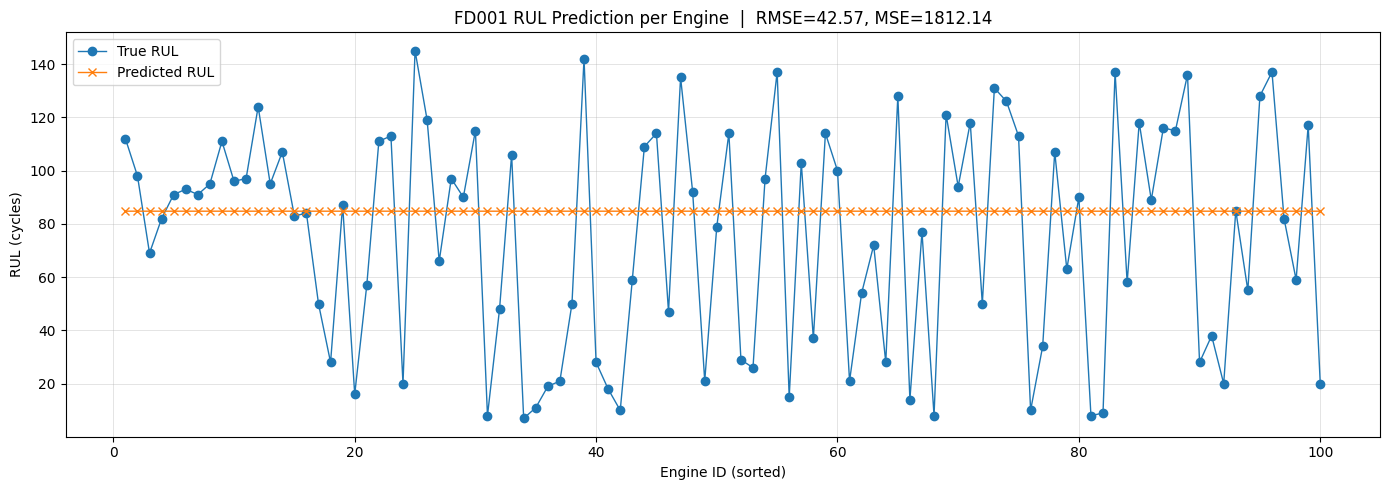

In [118]:
# =======================
# 7) Plot: each engine's RUL prediction vs ground truth
# =======================
plt.figure(figsize=(14,5))
x = np.arange(len(y_true_test)) + 1  # engine index 1..E
plt.plot(x, y_true_test, marker='o', linewidth=1, label='True RUL')
plt.plot(x, y_pred_test, marker='x', linewidth=1, label='Predicted RUL')
plt.xlabel('Engine ID (sorted)')
plt.ylabel('RUL (cycles)')
plt.title(f'FD001 RUL Prediction per Engine  |  RMSE={rmse:.2f}, MSE={mse:.2f}')
plt.legend()
plt.grid(True, linewidth=0.4, alpha=0.6)
plt.tight_layout()
plt.show()

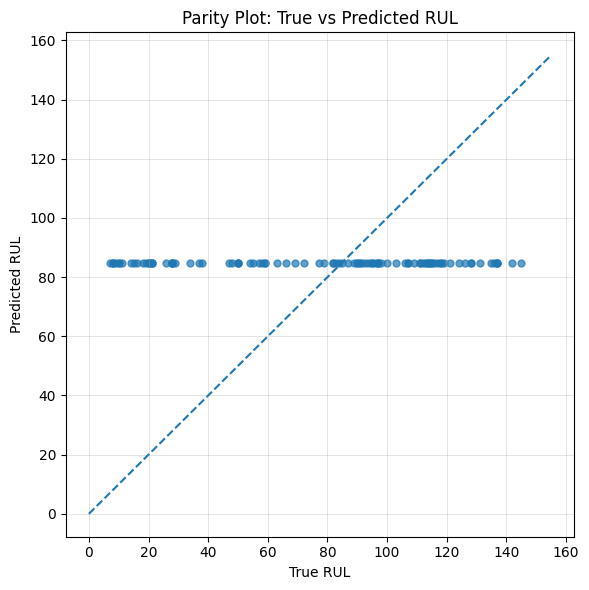

In [119]:
# Optional: scatter with y=x reference
plt.figure(figsize=(6,6))
plt.scatter(y_true_test, y_pred_test, s=25, alpha=0.7)
max_ax = max(float(y_true_test.max()), float(y_pred_test.max())) + 10
plt.plot([0, max_ax],[0, max_ax], linestyle='--')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Parity Plot: True vs Predicted RUL')
plt.grid(True, linewidth=0.4, alpha=0.6)
plt.tight_layout()
plt.show()